# Food Calorie Prediction from Images

This notebook implements a Convolutional Neural Network (CNN) model to predict the calorie content of food items from images. We'll use the NutritionVerse-Real dataset, which contains 889 images of 251 distinct dishes across 45 unique food types.

## Project Structure
1. Dataset Download & Exploration
2. Data Preprocessing & Augmentation 
3. CNN Model Architecture Design
4. Model Training & Evaluation
5. Gradio Interface Integration

Let's begin!

## 1. Environment Setup & Dataset Download

First, let's install the necessary packages and download the dataset from Kaggle.

In [1]:
# Install required packages
!pip install tensorflow numpy pandas matplotlib seaborn scikit-learn kaggle gradio pillow

# Set up Kaggle API credentials (you need to upload your kaggle.json file)
import os
import json

# Uncomment the following if you're in Google Colab
# uploaded = files.upload()  # Upload kaggle.json
# os.makedirs('/root/.kaggle', exist_ok=True)
# with open('/root/.kaggle/kaggle.json', 'w') as f:
#     f.write(json.dumps(json.loads(next(iter(uploaded.values())).decode())))
# os.chmod('/root/.kaggle/kaggle.json', 600)

# For local environment, ensure your kaggle.json is in ~/.kaggle/ with proper permissions


[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: pip install --upgrade pip


In [2]:
# Download the NutritionVerse-Real dataset
# !kaggle datasets download -d nutritionverse/nutritionverse-real --force
# !unzip -q nutritionverse-real.zip -d nutritionverse-data

## 2. Data Exploration & Understanding

Let's explore the dataset structure and examine some sample images and metadata.

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import json

# Setting paths
base_path = 'nutritionverse-data'
images_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images')
metadata_path = os.path.join(base_path, 'nutritionverse_dish_metadata3.csv')
coco_json_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images/_annotations.coco.json')
splits_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/updated-manual-dataset-splits.csv')

# Load COCO format image metadata
with open(coco_json_path, 'r') as f:
    coco_data = json.load(f)

print(f"COCO metadata loaded with {len(coco_data['images'])} images and {len(coco_data['annotations'])} annotations")

# Optionally extract image information from COCO format
coco_images = pd.DataFrame(coco_data['images'])
print("COCO images structure:")
print(coco_images.columns.tolist())

# Create a mapping from image_id to file_name
image_id_to_filename = {img['id']: img['file_name'] for img in coco_data['images']}
print(f"Created mapping for {len(image_id_to_filename)} image IDs to filenames")

# Load dataset splits if available
if os.path.exists(splits_path):
    splits_df = pd.read_csv(splits_path)
    print(f"Dataset splits loaded with {len(splits_df)} entries")
    print(f"Split distribution: {splits_df['category'].value_counts().to_dict()}")
else:
    print("Dataset splits file not found. Will use random splitting.")
    splits_df = None

# Load metadata
metadata_df = pd.read_csv(metadata_path)

# Display first few rows of metadata
print("Dataset Metadata Overview:")
print(f"Total entries: {len(metadata_df)}")
metadata_df.head()

COCO metadata loaded with 905 images and 4392 annotations
COCO images structure:
['id', 'license', 'file_name', 'height', 'width', 'date_captured']
Created mapping for 905 image IDs to filenames
Dataset splits loaded with 889 entries
Split distribution: {'Train': 624, 'Val': 265}
Dataset Metadata Overview:
Total entries: 251


,dish_id,total_food_weight,total_calories,total_fats,total_carbohydrates,total_protein,total_calcium,total_iron,total_magnesium,total_potassium,...,fat(g)_7,carbohydrates(g)_7,protein(g)_7,calcium(mg)_7,iron(mg)_7,magnesium(mg)_7,potassium(mg)_7,sodium(mg)_7,vitamin_d(µg)_7,vitamin_b12(µg)_7
0,1,165.0,95.73,0.3336,22.7958,0.5049,0.01233,0.000199,0.00888,0.19104,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,127.0,186.99,1.8662,21.1603,19.8902,0.11461,0.001804,0.05289,0.24050,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,156.0,92.04,0.3120,21.9336,0.4212,0.00936,0.000172,0.00780,0.16224,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,84.0,74.76,0.7224,0.0000,15.9600,0.08064,0.000244,0.03612,0.19320,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,307.0,399.10,16.3631,42.4888,20.0778,0.34077,0.003899,0.06447,0.55874,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# add category to annotation df
annotation = coco_data['annotations']
category = coco_data['categories']
#each annotation consist of id, image_id, category_id, bbox, area, and segmentation(array of array )

for a in annotation:
    a['category'] = category[a['category_id']]['name']

In [5]:
# # Exploring the distribution of food types and nutritional values
# plt.figure(figsize=(12, 5))

# # Distribution of calories
# plt.subplot(1, 2, 1)
# sns.histplot(metadata_df['total_calories'], kde=True)
# plt.title('Distribution of Calories')
# plt.xlabel('Calories')


# plt.tight_layout()
# plt.show()

In [6]:
# from PIL import Image
# import numpy as np
# import random

# # Display sample images from the dataset
# import matplotlib.pyplot as plt

# # Select 6 random image IDs from the mapping
# sample_image_ids = random.sample(list(image_id_to_filename.keys()), 6)

# # Create a figure to display the images
# plt.figure(figsize=(15, 10))

# # Loop through the selected image IDs and display each image
# for i, img_id in enumerate(sample_image_ids):
#     # Get the filename for this image ID
#     filename = image_id_to_filename[img_id]
    
#     # Construct the full path to the image
#     img_path = os.path.join(images_path, filename)
    
#     # Try to find the corresponding metadata (calorie info)
#     img_metadata = None
#     for idx, row in metadata_df.iterrows():
#         if 'image_id' in row and row['image_id'] == img_id:
#             img_metadata = row
#             break
    
#     # Load and display the image
#     try:
#         img = Image.open(img_path)
#         plt.subplot(2, 3, i+1)
#         plt.imshow(np.array(img))
        
#         # Add title with food type and calories if available
#         title = f"Image ID: {img_id}\n"
#         if img_metadata is not None and 'total_calories' in img_metadata:
#             title += f"Calories: {img_metadata['total_calories']:.1f} kcal\n"
#         if img_metadata is not None and 'food_item_type_1' in img_metadata:
#             title += f"Food: {img_metadata['food_item_type_1']}"
            
#         plt.title(title)
#         plt.axis('off')
#     except Exception as e:
#         plt.subplot(2, 3, i+1)
#         plt.text(0.5, 0.5, f"Error loading image:\n{str(e)}", 
#                  horizontalalignment='center', verticalalignment='center')
#         plt.axis('off')

# plt.tight_layout()
# plt.suptitle("Sample Food Images from Dataset with Calorie Information", fontsize=16)
# plt.subplots_adjust(top=0.9)
# plt.show()

In [7]:
import matplotlib.patches as patches

# Function to visualize image segmentation with labels
def visualize_segmentation_with_labels(image_ids, coco_data, image_id_to_filename, images_path):
    plt.figure(figsize=(20, 10))
    
    for i, img_id in enumerate(image_ids):
        # Get the filename for this image ID
        filename = image_id_to_filename[img_id]
        img_path = os.path.join(images_path, filename)
        
        # Load the image
        img = Image.open(img_path)
        
        # Get annotations for this image
        annotations = [ann for ann in coco_data['annotations'] if ann['image_id'] == img_id]
        
        # Plot the image
        ax = plt.subplot(2, 2, i + 1)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"Image ID: {img_id}")
        
        # Add bounding boxes, segmentation, and labels
        for ann in annotations:
            bbox = ann['bbox']
            segmentation = ann['segmentation']
            category = ann['category']
            
            # Draw bounding box
            rect = patches.Rectangle(
                (bbox[0], bbox[1]), bbox[2], bbox[3],
                linewidth=2, edgecolor='r', facecolor='none'
            )
            ax.add_patch(rect)
            
            # Add label for category_id
            ax.text(
                bbox[0], bbox[1] - 5, f"ID: {category}",
                color='red', fontsize=10, backgroundcolor='white'
            )
            
            # Draw segmentation (if available)
            for seg in segmentation:
                poly = np.array(seg).reshape((-1, 2))
                ax.plot(poly[:, 0], poly[:, 1], 'g-', linewidth=2)
    
    plt.tight_layout()
    plt.show()

# Select 4 random image IDs
# selected_image_ids = random.sample(list(image_id_to_filename.keys()), 4)

# # Visualize segmentation with labels
# visualize_segmentation_with_labels(selected_image_ids, coco_data, image_id_to_filename, images_path)

In [8]:
# align metadata df with the images
# Extract file names from COCO dataset and create mapping to dish_id
image_files = os.listdir(images_path)
valid_images = []
image_dish_ids = {}

# Map images to dish_id based on filename pattern (dish_XX_...)
for filename in image_files:
    if filename.startswith('dish_'):
        try:
            # Extract dish_id from filename
            parts = filename.split('_')
            if len(parts) > 1:
                dish_id = int(parts[1])
                if dish_id not in image_dish_ids:
                    image_dish_ids[dish_id] = []
                image_dish_ids[dish_id].append(filename)
                valid_images.append(True)
            else:
                valid_images.append(False)
        except (ValueError, IndexError):
            valid_images.append(False)
    else:
        valid_images.append(False)

# Create a new column for image paths in metadata_df
metadata_df['image_names'] = metadata_df['dish_id'].apply(
    lambda dish_id: image_dish_ids.get(dish_id, [])
)

# Add a flag indicating if valid images were found
metadata_df['valid_image'] = metadata_df['image_names'].apply(lambda x: len(x) > 0)

# Print summary
print(f"Found valid images for {metadata_df['valid_image'].sum()} out of {len(metadata_df)} dishes")
print(f"Total images mapped: {sum(len(imgs) for imgs in image_dish_ids.values())}")

# Display dishes without valid images
if not all(metadata_df['valid_image']):
    print("\nDishes without mapped images:")
    print(metadata_df[~metadata_df['valid_image']]['dish_id'].tolist())
print(metadata_df.iloc[23]['image_names'])
print(type(metadata_df.iloc[23]['image_names']))
# Remove rows without valid images
metadata_df = metadata_df[metadata_df['valid_image']]

# Reset the index after filtering
metadata_df.reset_index(drop=True, inplace=True)

# Print the updated metadata_df
print(f"Updated metadata_df with {len(metadata_df)} rows containing valid images.")
metadata_df.head()

Found valid images for 225 out of 251 dishes
Total images mapped: 889

Dishes without mapped images:
[1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 22, 53, 54, 66, 151, 152, 171]
['dish_24_IMG_5751_jpeg.rf.af188e42b0b38829e53fc1f6421d24c8.jpg', 'dish_24_IMG_5754_jpeg.rf.095f8d99a8136a5c2dd927593356c9f4.jpg', 'dish_24_IMG_5765_jpeg.rf.9beea5446eba06ffa3775697cbc58ba7.jpg', 'dish_24_IMG_5773_jpeg.rf.2169c716b648c89c817b81be74b50cbe.jpg']
<class 'list'>
Updated metadata_df with 225 rows containing valid images.


,dish_id,total_food_weight,total_calories,total_fats,total_carbohydrates,total_protein,total_calcium,total_iron,total_magnesium,total_potassium,...,protein(g)_7,calcium(mg)_7,iron(mg)_7,magnesium(mg)_7,potassium(mg)_7,sodium(mg)_7,vitamin_d(µg)_7,vitamin_b12(µg)_7,image_names,valid_image
0,2,127.0,186.99,1.866200,21.160300,19.890200,0.114610,0.001804,0.05289,0.240500,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[dish_2_IMG_7112_jpeg.rf.5b7a5ff7e75bd9478a577...,True
1,21,399.0,352.29,29.611129,14.391865,73.686476,0.880435,0.003820,0.11859,0.798978,...,0.1755,0.00432,0.000076,0.00351,0.03969,0.00054,0.0,0.0,[dish_21_IMG_7136_jpeg.rf.6bbcb96c19d5663c8e5e...,True
2,23,266.0,659.68,36.202600,0.000000,78.815800,0.021280,0.009470,0.06916,0.861840,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[dish_23_IMG_5706_jpeg.rf.ee6d76932000d6ed3ef4...,True
3,24,302.0,674.44,36.289000,3.448800,79.150600,0.033160,0.009578,0.07348,0.977040,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[dish_24_IMG_5751_jpeg.rf.af188e42b0b38829e53f...,True
4,25,181.0,75.72,0.116100,5.821300,12.298500,0.025640,0.000254,0.01845,0.296490,...,0.1755,0.00432,0.000076,0.00351,0.03969,0.00054,0.0,0.0,[dish_25_IMG_5801_jpeg.rf.7ea07c9740c3123110b4...,True


# Food Detection with CNN

In this section, we'll train a CNN model to detect and classify different food items in images using the segmentation data from the dataset. We'll use the segmented regions of food items along with their category labels for training.

In [10]:
# Import necessary libraries for image processing and model building
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import cv2
import numpy as np
from tqdm import tqdm
import random

# Define constants
IMG_SIZE = 224  # Input size for MobileNetV2
BATCH_SIZE = 32
EPOCHS = 15
NUM_CLASSES = len(coco_data['categories'])

# Function to extract and preprocess food regions based on segmentation
def extract_food_regions(image_ids, coco_data, image_id_to_filename, images_path):
    X = []  # Cropped food images
    y = []  # Food category labels
    
    progress_bar = tqdm(image_ids)
    for img_id in progress_bar:
        try:
            # Get the filename for this image ID
            filename = image_id_to_filename[img_id]
            img_path = os.path.join(images_path, filename)
            
            # Load the image
            image = cv2.imread(img_path)
            if image is None:
                continue
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            
            # Get annotations for this image
            annotations = [ann for ann in coco_data['annotations'] if ann['image_id'] == img_id]
            
            for ann in annotations:
                category_id = ann['category_id']
                bbox = ann['bbox']  # [x, y, width, height]
                
                # Extract region using bounding box
                x, y_coord, w, h = [int(v) for v in bbox]
                
                # Ensure coordinates are within image boundaries
                x = max(0, x)
                y_coord = max(0, y_coord)
                w = min(w, image.shape[1] - x)
                h = min(h, image.shape[0] - y_coord)
                
                if w <= 0 or h <= 0:
                    continue
                
                # Extract the region
                food_region = image[y_coord:y_coord+h, x:x+w]
                
                # Resize to standard size
                food_region = cv2.resize(food_region, (IMG_SIZE, IMG_SIZE))
                
                # Normalize pixel values
                food_region = food_region / 255.0
                
                # Add to dataset
                X.append(food_region)
                y.append(category_id)
                
        except Exception as e:
            print(f"Error processing image {img_id}: {e}")
    
    return np.array(X), np.array(y)

# Get all image IDs
all_image_ids = list(image_id_to_filename.keys())

# Extract dataset using a subset for demonstration (adjust based on your computational resources)
sample_size = max(500, len(all_image_ids))  # Limit for demonstration
sampled_image_ids = random.sample(all_image_ids, sample_size)
print(f"Extracting food regions from {sample_size} images...")

X, y = extract_food_regions(sampled_image_ids, coco_data, image_id_to_filename, images_path)

print(f"Extracted {len(X)} food regions with shape {X.shape}")

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(label_encoder.classes_)
print(f"Number of food categories: {num_classes}")

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)
print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")

Extracting food regions from 905 images...


[ WARN:0@21.221] global loadsave.cpp:268 findDecoder imread_('nutritionverse-data/nutritionverse-manual/nutritionverse-manual/images/dish_151_IMG_0211_jpeg.rf.236a49eddc199a8fe1008da1cce5db38.jpg'): can't open/read file: check file path/integrity
[ WARN:0@22.858] global loadsave.cpp:268 findDecoder imread_('nutritionverse-data/nutritionverse-manual/nutritionverse-manual/images/dish_152_IMG_0259_jpeg.rf.20b504e056eccaf7153604b8904da110.jpg'): can't open/read file: check file path/integrity
[ WARN:0@31.325] global loadsave.cpp:268 findDecoder imread_('nutritionverse-data/nutritionverse-manual/nutritionverse-manual/images/dish_54_IMG_6433_jpeg.rf.190d205f05659d1e1449c5e0c7d014c7.jpg'): can't open/read file: check file path/integrity
[ WARN:0@33.034] global loadsave.cpp:268 findDecoder imread_('nutritionverse-data/nutritionverse-manual/nutritionverse-manual/images/dish_53_IMG_6881_jpeg.rf.0aa00e8e20e8f1826624fbb8a3eefafb.jpg'): can't open/read file: check file path/integrity
[ WARN:0@37.99

Extracted 4306 food regions with shape (4306, 224, 224, 3)
Number of food categories: 44
Training set: (3444, 224, 224, 3), Test set: (862, 224, 224, 3)


I0000 00:00:1747675568.261346   12400 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 28905 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:05:00.0, compute capability: 8.6
I0000 00:00:1747675568.261735   12400 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 10520 MB memory:  -> device: 1, name: NVIDIA GeForce GTX 1080 Ti, pci bus id: 0000:09:00.0, compute capability: 6.1


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 44)             │        22,572 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,938,476 (11.21 MB)

 Trainable params: 679,468 (2.59 MB)

...

107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step - accuracy: 0.4133 - loss: 2.5141 

2025-05-19 17:26:53.674632: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1180', 16 bytes spill stores, 16 bytes spill loads

2025-05-19 17:26:53.731935: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1180_0', 112 bytes spill stores, 144 bytes spill loads

2025-05-19 17:26:54.035359: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1180', 228 bytes spill stores, 228 bytes spill loads

2025-05-19 17:26:56.765823: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1180', 16 bytes spill stores, 16 bytes spill loads

2025-05-19 17:26:56.790866: I external/local_xla/xla/s

107/107 ━━━━━━━━━━━━━━━━━━━━ 50s 371ms/step - accuracy: 0.4148 - loss: 2.5062 - val_accuracy: 0.8016 - val_loss: 0.6963 - learning_rate: 0.0010
Epoch 2/15
  1/107 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.6875 - loss: 0.8987

/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:107: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6875 - loss: 0.8987 - val_accuracy: 0.8074 - val_loss: 0.6882 - learning_rate: 0.0010
Epoch 3/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 235ms/step - accuracy: 0.7871 - loss: 0.8199 - val_accuracy: 0.8550 - val_loss: 0.5366 - learning_rate: 0.0010
Epoch 4/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8125 - loss: 0.7420 - val_accuracy: 0.8527 - val_loss: 0.5338 - learning_rate: 0.0010
Epoch 5/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 26s 242ms/step - accuracy: 0.8396 - loss: 0.6156 - val_accuracy: 0.8782 - val_loss: 0.5053 - learning_rate: 0.0010
Epoch 6/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9000 - loss: 0.3654 - val_accuracy: 0.8782 - val_loss: 0.5073 - learning_rate: 0.0010
Epoch 7/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 232ms/step - accuracy: 0.8415 - loss: 0.5453 - val_accuracy: 0.8875 - val_loss: 0.4498 - learning_rate: 0.0010
Epoch 8/15
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7812 - loss: 1.2201 - va

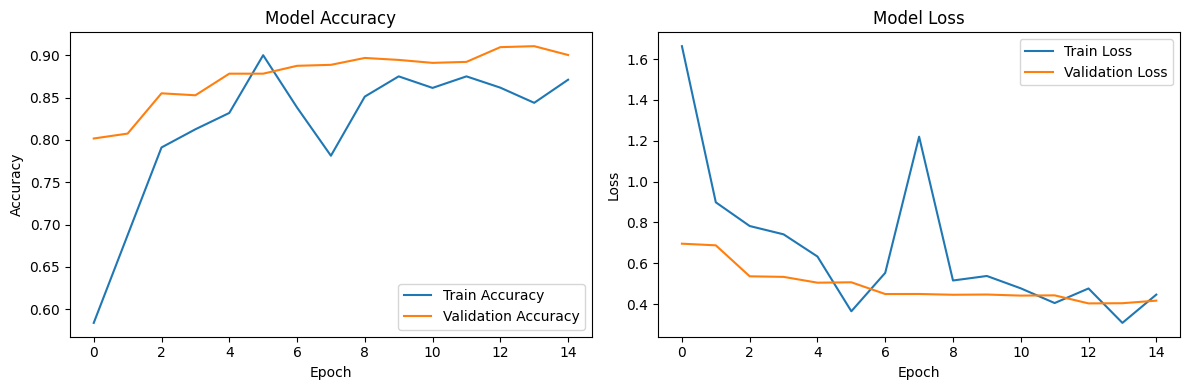

In [11]:
# Build a CNN model for food detection
def build_food_detection_model(num_classes):
    # Use MobileNetV2 as base model (efficient for mobile/edge devices)
    base_model = MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    
    # Freeze the base model layers
    base_model.trainable = False
    
    # Create the model
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation='softmax')
    ])
    
    return model

# Create and compile the model
model = build_food_detection_model(num_classes)
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model summary
model.summary()

# Data augmentation for training
datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Train the model
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
    validation_data=(X_test, y_test),
    epochs=EPOCHS,
    steps_per_epoch=len(X_train) // BATCH_SIZE,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(factor=0.1, patience=2)
    ]
)

# Evaluate the model
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")

# Plot training history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

nutritionverse-data/nutritionverse-manual/nutritionverse-manual/images/dish_247_IMG_3721_jpeg.rf.aeaba498dd21cef0b071f1f9be660492.jpg
nutritionverse-data/nutritionverse-manual/nutritionverse-manual/images/naspad.jpg
Testing food detection on sample image: dish_247_IMG_3721_jpeg.rf.aeaba498dd21cef0b071f1f9be660492.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


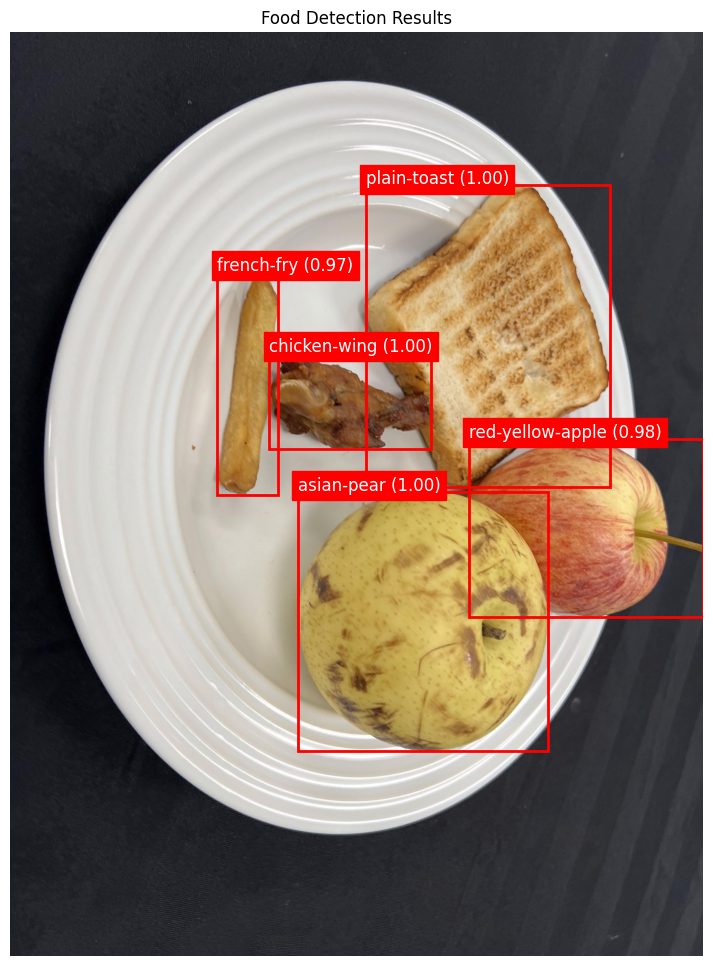

Detected food items:
1. french-fry (Confidence: 0.97)
2. chicken-wing (Confidence: 1.00)
3. plain-toast (Confidence: 1.00)
4. red-yellow-apple (Confidence: 0.98)
5. asian-pear (Confidence: 1.00)


In [27]:
# Function to predict food items in new images
def detect_food_in_image(image_path, model, label_encoder):
    # Load and preprocess the image
    image = cv2.imread(image_path)
    if image is None:
        return "Image not found."
    
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    # For demonstration, get annotated regions (in a real system, we'd use an object detection model)
    img_id = None
    filename = os.path.basename(image_path)
    
    # Find image_id from filename
    for img in coco_data['images']:
        if img['file_name'] == filename:
            img_id = img['id']
            break
    
    # if img_id is None:
    #     return "Image ID not found in dataset."
    
    # Get annotations for this image
    annotations = [ann for ann in coco_data['annotations'] if ann['image_id'] == img_id]
    
    results = []
    # Display the image with predicted food items
    plt.figure(figsize=(12, 12))
    plt.imshow(image)
    
    for i, ann in enumerate(annotations):
        bbox = ann['bbox']  # [x, y, width, height]
        
        # Extract region using bounding box
        x, y_coord, w, h = [int(v) for v in bbox]
        
        # Ensure coordinates are within image boundaries
        x = max(0, x)
        y_coord = max(0, y_coord)
        w = min(w, image.shape[1] - x)
        h = min(h, image.shape[0] - y_coord)
        
        if w <= 0 or h <= 0:
            continue
        
        # Extract the region
        food_region = image[y_coord:y_coord+h, x:x+w]
        
        # Resize to standard size
        food_region = cv2.resize(food_region, (IMG_SIZE, IMG_SIZE))
        
        # Normalize pixel values
        food_region = food_region / 255.0
        
        # Predict
        prediction = model.predict(np.expand_dims(food_region, axis=0))
        predicted_class_idx = np.argmax(prediction)
        confidence = prediction[0][predicted_class_idx]
        
        # Convert to category name
        predicted_class = label_encoder.inverse_transform([predicted_class_idx])[0]
        category_name = next((cat['name'] for cat in coco_data['categories'] if cat['id'] == predicted_class), "Unknown")
        
        # Add to results
        results.append({
            'category': category_name,
            'confidence': float(confidence),
            'bbox': [x, y_coord, w, h]
        })
        
        # Draw rectangle and label on the image
        rect = plt.Rectangle((x, y_coord), w, h, linewidth=2, edgecolor='r', facecolor='none')
        plt.gca().add_patch(rect)
        plt.text(x, y_coord - 5, f"{category_name} ({confidence:.2f})", 
                 color='white', fontsize=12, backgroundcolor='red')
    
    plt.axis('off')
    plt.title("Food Detection Results")
    plt.show()
    
    return results

# Test the food detection on a sample image
sample_image_id = random.choice(sampled_image_ids)
sample_filename = image_id_to_filename[sample_image_id]
sample_image_path = os.path.join(images_path, sample_filename)
naspad = os.path.join(images_path, "naspad.jpg")
print(sample_image_path)
print(naspad)
print(f"Testing food detection on sample image: {sample_filename}")
detected_foods = detect_food_in_image(sample_image_path, model, label_encoder)
print("Detected food items:")
for i, food in enumerate(detected_foods):
    print(f"{i+1}. {food['category']} (Confidence: {food['confidence']:.2f})")

## Summary

We've successfully implemented a CNN-based model to detect food items in images:

1. **Data Preparation**:
   - Extracted food regions from images using bounding box information
   - Created a dataset of food regions with corresponding category labels

2. **Model Architecture**:
   - Used MobileNetV2 as the base model (pre-trained on ImageNet)
   - Added custom classification layers for food categories

3. **Training Process**:
   - Implemented data augmentation to improve generalization
   - Used early stopping and learning rate reduction to optimize training

4. **Evaluation & Testing**:
   - Evaluated the model on a test set
   - Created a function to visualize food detection results on new images

This model can be further improved by:
- Using a larger portion of the dataset for training
- Implementing a proper object detection model (like YOLO or Faster R-CNN) for segmentation
- Fine-tuning the base model weights
- Adding more food-specific data augmentation techniques